# Analysis — Experiment 1: K-Shot Ablation Results

Notebook ini menganalisis hasil Experiment 1 (K-Shot Ablation, strategy=random) dari file `results-exp-1/all_results.jsonl`.

**Output:**
- Tabel metrik per k-shot per test set
- Grafik performa (Accuracy, F1, Sensitivity, Specificity)
- Confusion matrix heatmap
- Inference time analysis
- Generalization gap (Internal vs External)
- Statistical significance tests

## 1 — Load Data

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from scipy import stats
from pathlib import Path
import re
import warnings
warnings.filterwarnings('ignore')

# Style
matplotlib.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
sns.set_palette('colorblind')

RESULTS_DIR = Path('results-exp-1')
FIGURES_DIR = Path('figures-exp-1')
FIGURES_DIR.mkdir(exist_ok=True)

# Load JSONL
records = []
with open(RESULTS_DIR / 'all_results.jsonl', encoding='utf-8') as f:
    for line in f:
        records.append(json.loads(line.strip()))

df = pd.DataFrame(records)
print(f'Total records: {len(df)}')
print(f'Columns: {list(df.columns)}')
print(f'k_shots: {sorted(df["k_shot"].unique())}')
print(f'seeds: {sorted(df["seed"].unique())}')
print(f'test_sets: {df["test_set"].unique().tolist()}')

Total records: 11950
Columns: ['experiment_type', 'model_id', 'model_name', 'prompt_version', 'k_shot', 'strategy', 'seed', 'test_set', 'image_id', 'ground_truth', 'generated_text', 'inference_time', 'timestamp']
k_shots: [np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8)]
seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']


## 2 — Extract Predictions dari Generated Text

In [2]:
def extract_diagnosis(text):
    """
    Ekstrak diagnosis dari output model.
    Model menghasilkan format: <think>...</think><answer>...</answer>
    """
    text = str(text)
    
    # Coba ekstrak dari tag <answer>
    answer_match = re.search(r'<answer>\s*(.*?)\s*</answer>', text, re.IGNORECASE | re.DOTALL)
    if answer_match:
        answer = answer_match.group(1).strip().lower()
        if 'pneumothorax' in answer:
            return 1
        elif 'no finding' in answer or 'normal' in answer:
            return 0
    
    # Fallback: cek dari keseluruhan teks
    text_lower = text.lower()
    
    neg_keywords = [
        'no pneumothorax', 'no evidence of pneumothorax',
        'without pneumothorax', 'pneumothorax is not',
        'no finding'
    ]
    for nk in neg_keywords:
        if nk in text_lower:
            return 0
    
    pos_keywords = ['pneumothorax']
    for pk in pos_keywords:
        if pk in text_lower:
            return 1
    
    return 0  # default


df['predicted'] = df['generated_text'].apply(extract_diagnosis)

print('Distribusi prediksi:')
print(df['predicted'].value_counts())
print(f'\nDistribusi ground truth:')
print(df['ground_truth'].value_counts())
print(f'\nMatch rate (overall): {(df["predicted"] == df["ground_truth"]).mean():.4f}')

Distribusi prediksi:
predicted
0    10174
1     1776
Name: count, dtype: int64

Distribusi ground truth:
ground_truth
1    6825
0    5125
Name: count, dtype: int64

Match rate (overall): 0.5151


## 3 — Compute Metrics per (k_shot, seed, test_set)

In [3]:
def compute_metrics(y_true, y_pred):
    """Hitung semua classification metrics."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'sensitivity': recall_score(y_true, y_pred, zero_division=0),        # recall for positive
        'specificity': recall_score(y_true, y_pred, pos_label=0, zero_division=0),  # recall for negative
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'tp': tp, 'tn': tn, 'fp': fp, 'fn': fn,
    }


# Per-seed metrics
per_seed_rows = []
for (k, seed, ts), grp in df.groupby(['k_shot', 'seed', 'test_set']):
    m = compute_metrics(grp['ground_truth'].tolist(), grp['predicted'].tolist())
    per_seed_rows.append({'k_shot': k, 'seed': seed, 'test_set': ts, **m})

per_seed_df = pd.DataFrame(per_seed_rows)

# Mean +/- std across seeds
METRIC_COLS = ['accuracy', 'sensitivity', 'specificity', 'precision', 'f1']

summary_rows = []
for (k, ts), grp in per_seed_df.groupby(['k_shot', 'test_set']):
    row = {'k_shot': k, 'test_set': ts}
    for col in METRIC_COLS:
        row[f'{col}_mean'] = grp[col].mean()
        row[f'{col}_std'] = grp[col].std()
    # mean inference time
    k_ts_df = df[(df['k_shot'] == k) & (df['test_set'] == ts)]
    row['time_mean'] = k_ts_df['inference_time'].mean()
    row['time_std'] = k_ts_df['inference_time'].std()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).sort_values(['test_set', 'k_shot'])

# Display
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

for ts in summary_df['test_set'].unique():
    print(f'\n{"="*60}')
    print(f'  {ts}')
    print(f'{"="*60}')
    sub = summary_df[summary_df['test_set'] == ts][['k_shot'] + 
          [f'{m}_mean' for m in METRIC_COLS] + [f'{m}_std' for m in METRIC_COLS]]
    
    # Format nice table
    for _, r in sub.iterrows():
        print(f"  k={int(r['k_shot']):d}  |  "
              f"Acc={r['accuracy_mean']:.4f}\u00b1{r['accuracy_std']:.4f}  "
              f"F1={r['f1_mean']:.4f}\u00b1{r['f1_std']:.4f}  "
              f"Sens={r['sensitivity_mean']:.4f}\u00b1{r['sensitivity_std']:.4f}  "
              f"Spec={r['specificity_mean']:.4f}\u00b1{r['specificity_std']:.4f}")


  CheXpert Plus (Internal)
  k=0  |  Acc=0.5430±0.0045  F1=0.2370±0.0116  Sens=0.1420±0.0084  Spec=0.9440±0.0089
  k=1  |  Acc=0.5550±0.0468  F1=0.2377±0.1638  Sens=0.1500±0.1120  Spec=0.9600±0.0200
  k=2  |  Acc=0.5670±0.0271  F1=0.3238±0.0862  Sens=0.2120±0.0694  Spec=0.9220±0.0466
  k=4  |  Acc=0.5970±0.0104  F1=0.4700±0.0222  Sens=0.3580±0.0268  Spec=0.8360±0.0241
  k=8  |  Acc=0.6010±0.0147  F1=0.5312±0.0326  Sens=0.4540±0.0462  Spec=0.7480±0.0342

  RS UNAIR (External)
  k=0  |  Acc=0.4022±0.0059  F1=0.0857±0.0173  Sens=0.0451±0.0095  Spec=0.9905±0.0000
  k=1  |  Acc=0.4158±0.0299  F1=0.1158±0.0886  Sens=0.0636±0.0506  Spec=0.9962±0.0052
  k=2  |  Acc=0.4525±0.0352  F1=0.2175±0.0891  Sens=0.1249±0.0566  Spec=0.9924±0.0043
  k=4  |  Acc=0.5058±0.0249  F1=0.3550±0.0695  Sens=0.2220±0.0596  Spec=0.9733±0.0383
  k=8  |  Acc=0.5921±0.0285  F1=0.5494±0.0660  Sens=0.4058±0.0753  Spec=0.8990±0.0507


## 4 — Figure 1: K-Shot Performance Curves (Accuracy & F1)

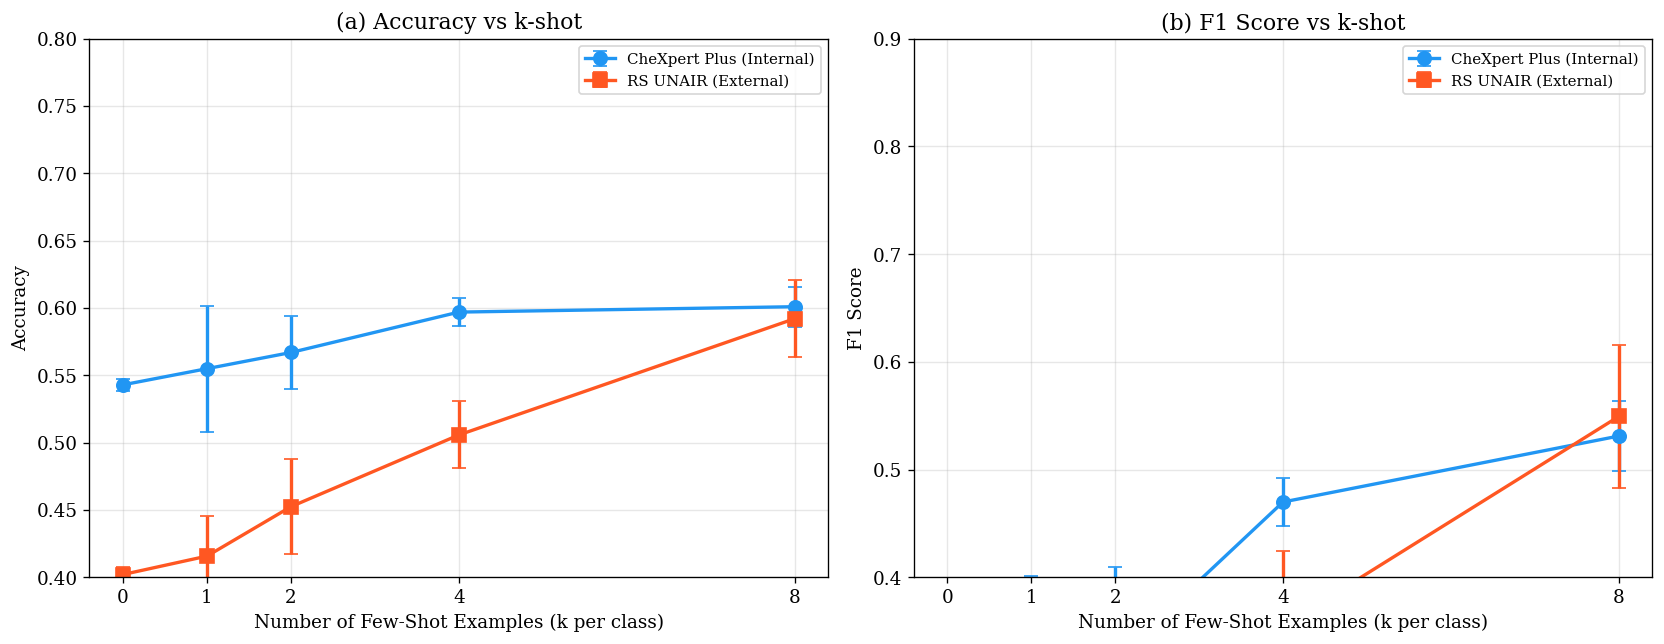

Saved: fig1_kshot_accuracy_f1


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

test_sets = summary_df['test_set'].unique()
colors_ts = {'CheXpert Plus (Internal)': '#2196F3', 'RS UNAIR (External)': '#FF5722'}
markers_ts = {'CheXpert Plus (Internal)': 'o', 'RS UNAIR (External)': 's'}

# (a) Accuracy
ax = axes[0]
for ts in test_sets:
    sub = summary_df[summary_df['test_set'] == ts].sort_values('k_shot')
    ax.errorbar(
        sub['k_shot'], sub['accuracy_mean'],
        yerr=sub['accuracy_std'],
        label=ts, marker=markers_ts.get(ts, 'o'),
        capsize=4, linewidth=2, color=colors_ts.get(ts, None),
        markersize=8
    )
ax.set_xlabel('Number of Few-Shot Examples (k per class)')
ax.set_ylabel('Accuracy')
ax.set_title('(a) Accuracy vs k-shot')
ax.set_xticks(sorted(df['k_shot'].unique()))
ax.legend(fontsize=9)
ax.set_ylim(0.4, 0.8)

# (b) F1 Score
ax = axes[1]
for ts in test_sets:
    sub = summary_df[summary_df['test_set'] == ts].sort_values('k_shot')
    ax.errorbar(
        sub['k_shot'], sub['f1_mean'],
        yerr=sub['f1_std'],
        label=ts, marker=markers_ts.get(ts, 'o'),
        capsize=4, linewidth=2, color=colors_ts.get(ts, None),
        markersize=8
    )
ax.set_xlabel('Number of Few-Shot Examples (k per class)')
ax.set_ylabel('F1 Score')
ax.set_title('(b) F1 Score vs k-shot')
ax.set_xticks(sorted(df['k_shot'].unique()))
ax.legend(fontsize=9)
ax.set_ylim(0.4, 0.9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_kshot_accuracy_f1.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig1_kshot_accuracy_f1.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig1_kshot_accuracy_f1')

## 5 — Figure 2: Sensitivity & Specificity Curves

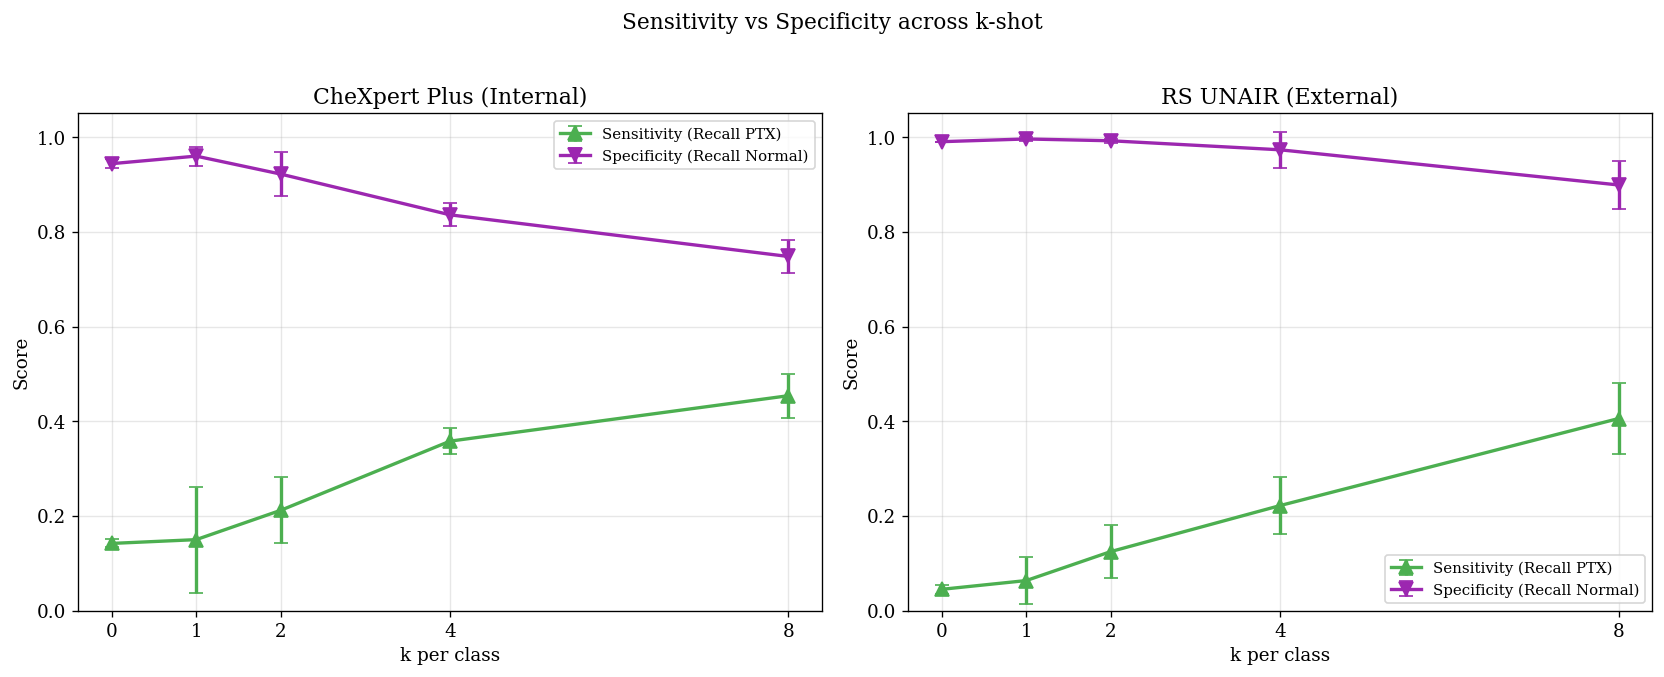

Saved: fig2_sensitivity_specificity


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_sets):
    ax = axes[idx]
    sub = summary_df[summary_df['test_set'] == ts].sort_values('k_shot')
    
    ax.errorbar(
        sub['k_shot'], sub['sensitivity_mean'], yerr=sub['sensitivity_std'],
        label='Sensitivity (Recall PTX)', marker='^',
        capsize=4, linewidth=2, color='#4CAF50', markersize=8
    )
    ax.errorbar(
        sub['k_shot'], sub['specificity_mean'], yerr=sub['specificity_std'],
        label='Specificity (Recall Normal)', marker='v',
        capsize=4, linewidth=2, color='#9C27B0', markersize=8
    )
    
    ax.set_xlabel('k per class')
    ax.set_ylabel('Score')
    ax.set_title(ts)
    ax.set_xticks(sorted(df['k_shot'].unique()))
    ax.legend(fontsize=9)
    ax.set_ylim(0.0, 1.05)

plt.suptitle('Sensitivity vs Specificity across k-shot', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_sensitivity_specificity.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig2_sensitivity_specificity.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig2_sensitivity_specificity')

## 6 — Figure 3: Confusion Matrices (0-shot vs best k-shot)

Best k (by F1 on internal): k=8


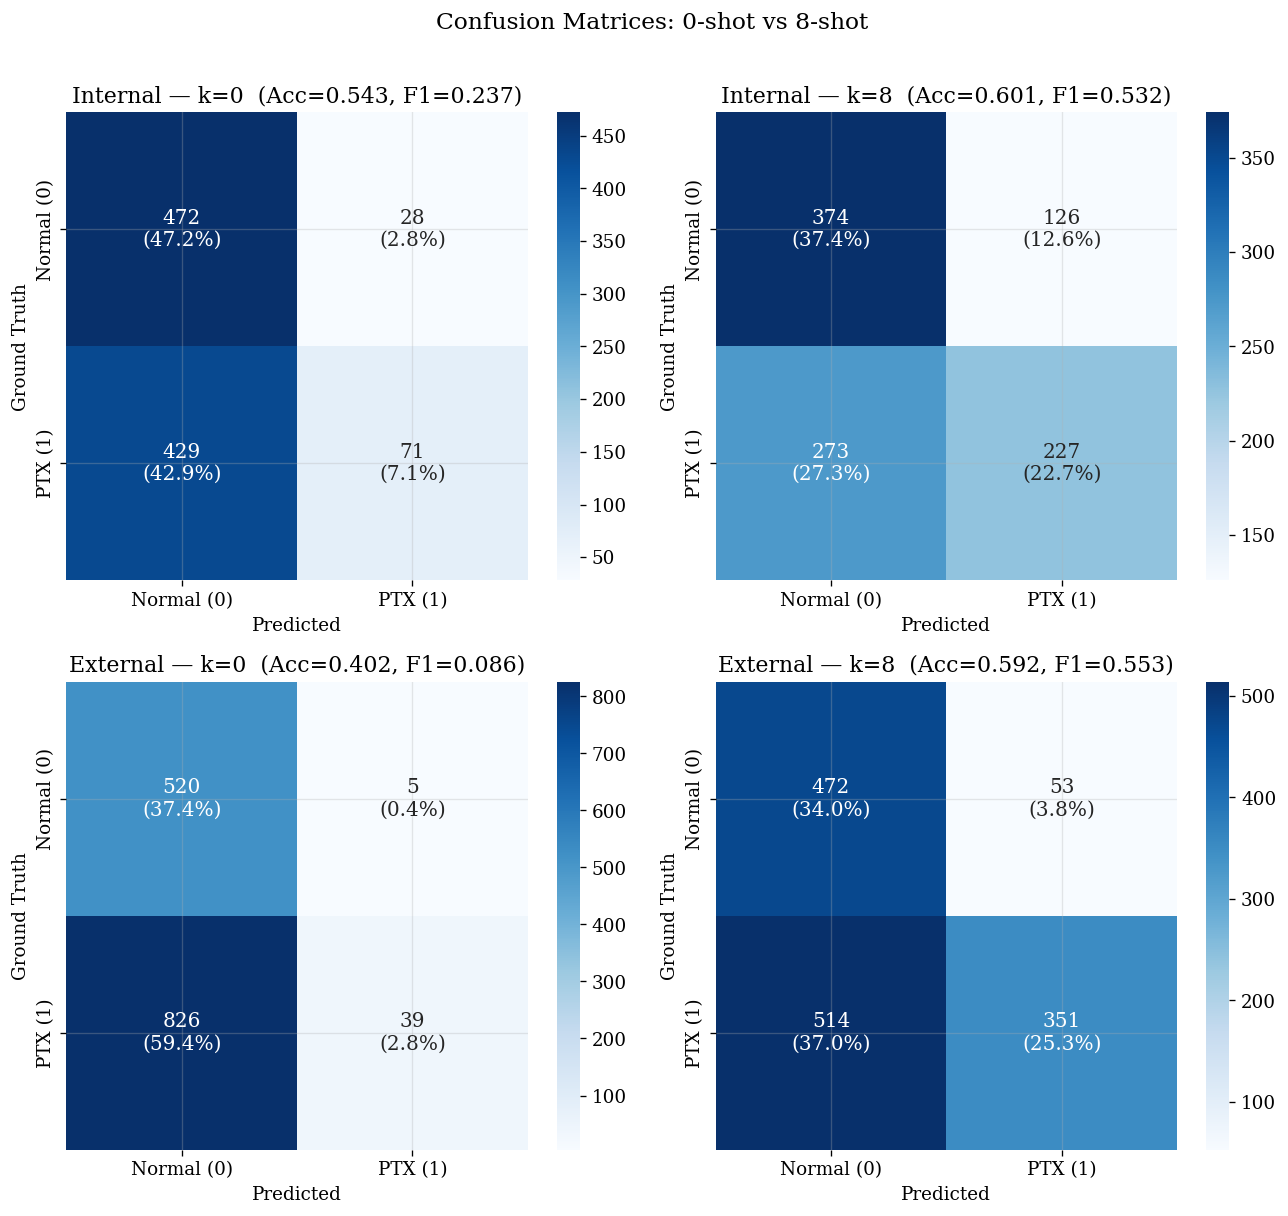

Saved: fig3_confusion_matrices


In [6]:
# Tentukan best_k dari F1 tertinggi di CheXpert internal
chex_summary = summary_df[summary_df['test_set'] == 'CheXpert Plus (Internal)']
best_k = int(chex_summary.loc[chex_summary['f1_mean'].idxmax(), 'k_shot'])
print(f'Best k (by F1 on internal): k={best_k}')

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

configs = [
    (0, 'CheXpert Plus (Internal)', axes[0, 0]),
    (best_k, 'CheXpert Plus (Internal)', axes[0, 1]),
    (0, 'RS UNAIR (External)', axes[1, 0]),
    (best_k, 'RS UNAIR (External)', axes[1, 1]),
]

for k_val, ts_name, ax in configs:
    sub = df[(df['k_shot'] == k_val) & (df['test_set'] == ts_name)]
    cm = confusion_matrix(sub['ground_truth'], sub['predicted'], labels=[0, 1])
    
    # Normalize for display
    cm_pct = cm.astype(float) / cm.sum() * 100
    
    # Annotation: count + percentage
    annot = np.array([
        [f'{cm[i,j]}\n({cm_pct[i,j]:.1f}%)' for j in range(2)]
        for i in range(2)
    ])
    
    sns.heatmap(
        cm, annot=annot, fmt='', cmap='Blues',
        xticklabels=['Normal (0)', 'PTX (1)'],
        yticklabels=['Normal (0)', 'PTX (1)'],
        ax=ax, cbar=True,
        annot_kws={'fontsize': 12}
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Ground Truth')
    
    # Compute acc for title
    acc = accuracy_score(sub['ground_truth'], sub['predicted'])
    f1 = f1_score(sub['ground_truth'], sub['predicted'], zero_division=0)
    short_ts = 'Internal' if 'Internal' in ts_name else 'External'
    ax.set_title(f'{short_ts} — k={k_val}  (Acc={acc:.3f}, F1={f1:.3f})')

plt.suptitle(f'Confusion Matrices: 0-shot vs {best_k}-shot', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig3_confusion_matrices.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig3_confusion_matrices.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig3_confusion_matrices')

## 7 — Figure 4: All Metrics Grouped Bar Chart

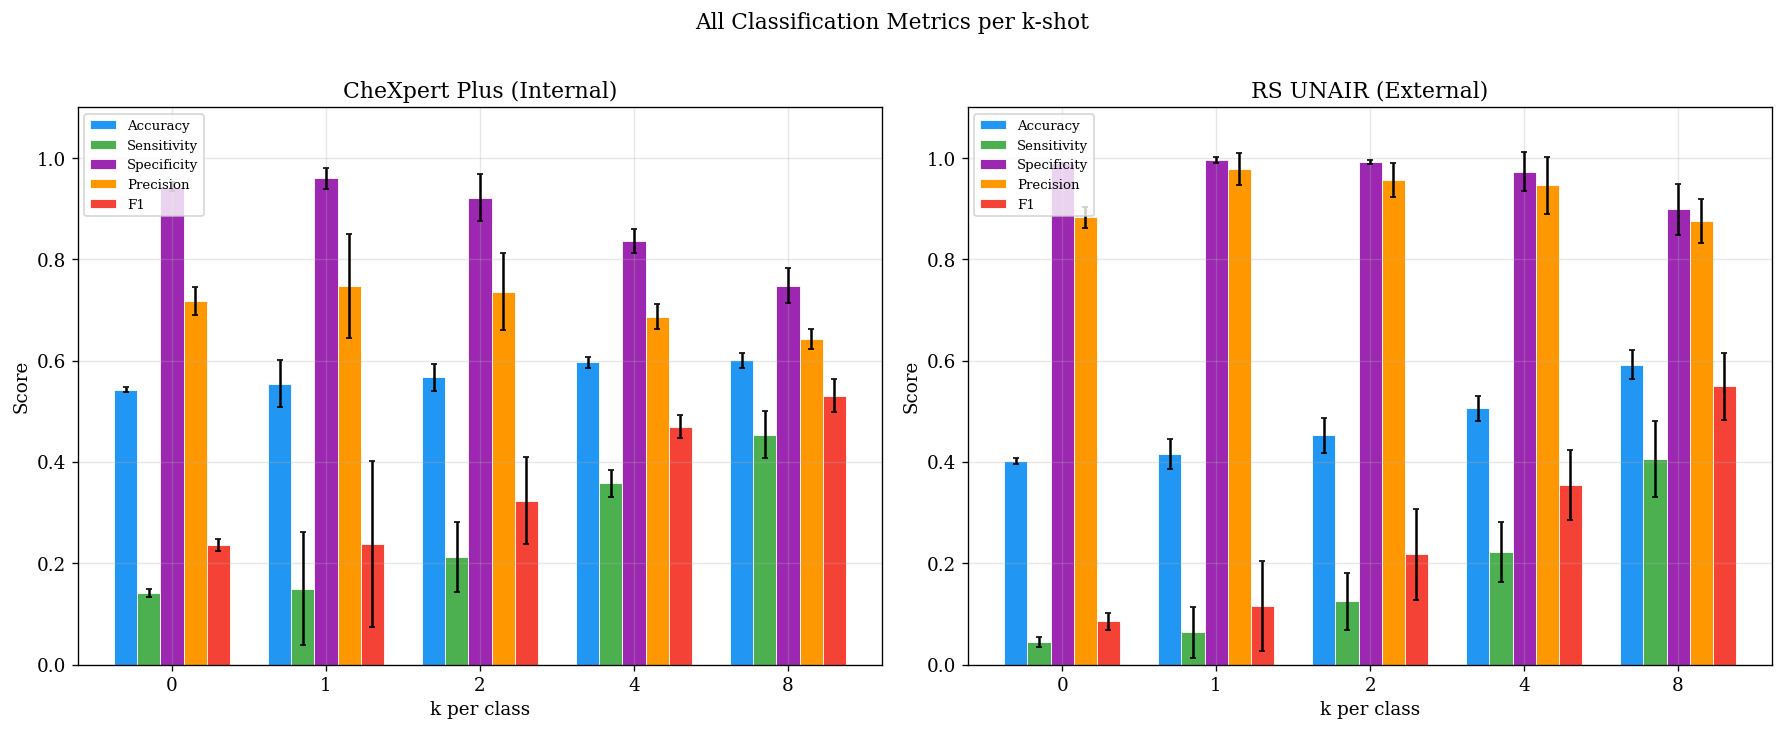

Saved: fig4_all_metrics_bar


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

k_shots = sorted(df['k_shot'].unique())
bar_width = 0.15
metric_labels = ['Accuracy', 'Sensitivity', 'Specificity', 'Precision', 'F1']
metric_keys = ['accuracy', 'sensitivity', 'specificity', 'precision', 'f1']
colors_met = ['#2196F3', '#4CAF50', '#9C27B0', '#FF9800', '#F44336']

for idx, ts in enumerate(test_sets):
    ax = axes[idx]
    sub = summary_df[summary_df['test_set'] == ts].sort_values('k_shot')
    x = np.arange(len(k_shots))
    
    for i, (mk, ml, mc) in enumerate(zip(metric_keys, metric_labels, colors_met)):
        vals = sub[f'{mk}_mean'].values
        errs = sub[f'{mk}_std'].values
        ax.bar(
            x + i * bar_width, vals, bar_width,
            yerr=errs, label=ml, color=mc,
            capsize=2, edgecolor='white', linewidth=0.5
        )
    
    ax.set_xlabel('k per class')
    ax.set_ylabel('Score')
    ax.set_title(ts)
    ax.set_xticks(x + bar_width * 2)
    ax.set_xticklabels([str(k) for k in k_shots])
    ax.legend(fontsize=8, loc='upper left')
    ax.set_ylim(0, 1.1)

plt.suptitle('All Classification Metrics per k-shot', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_all_metrics_bar.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig4_all_metrics_bar.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig4_all_metrics_bar')

## 8 — Figure 5: Per-Seed Scatter (Variance Visualization)

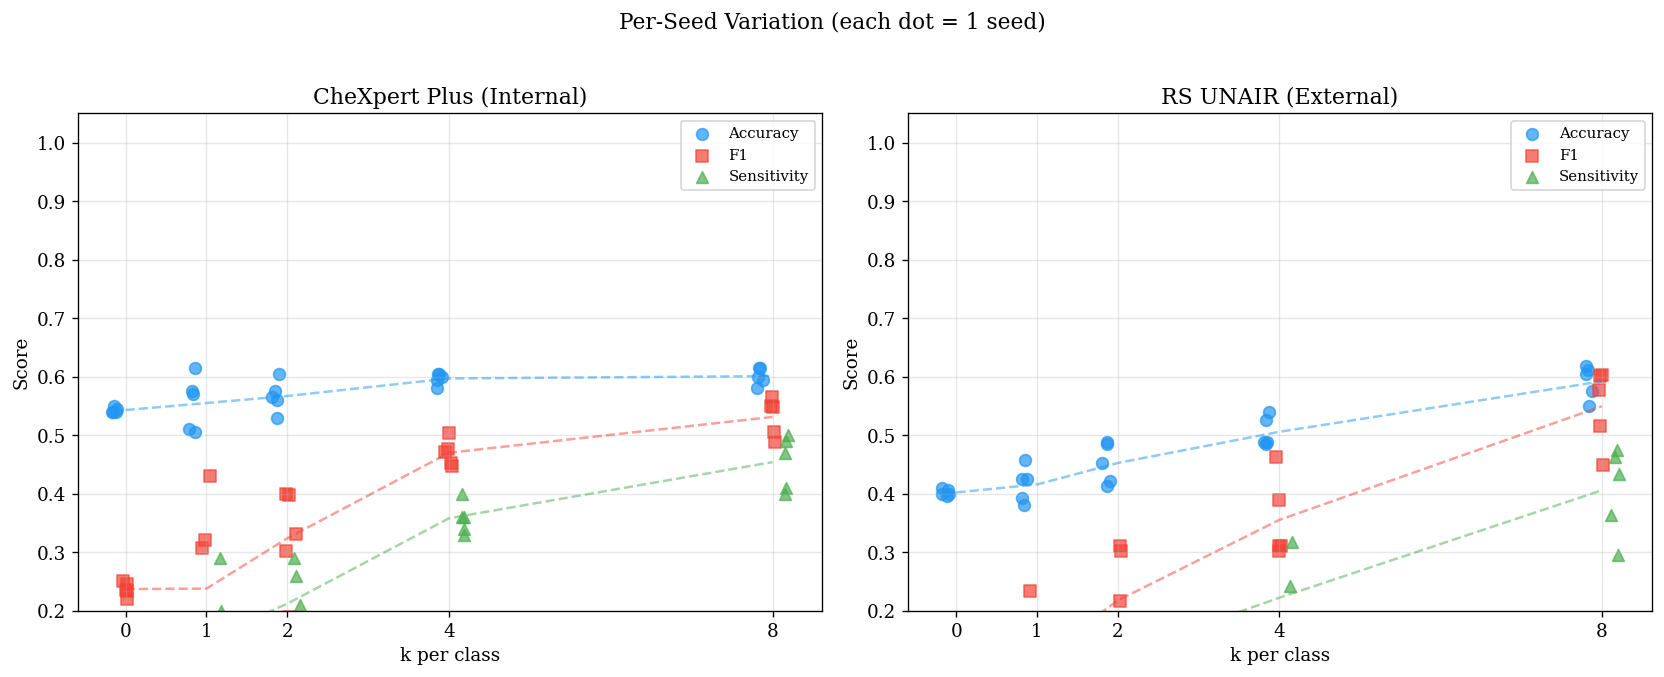

Saved: fig5_per_seed_scatter


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_sets):
    ax = axes[idx]
    sub = per_seed_df[per_seed_df['test_set'] == ts]
    
    # Jitter x-axis for visibility
    for metric, color, marker, offset in [
        ('accuracy', '#2196F3', 'o', -0.15),
        ('f1', '#F44336', 's', 0.0),
        ('sensitivity', '#4CAF50', '^', 0.15),
    ]:
        for k in sorted(sub['k_shot'].unique()):
            k_data = sub[sub['k_shot'] == k]
            jitter = np.random.normal(0, 0.03, len(k_data))
            ax.scatter(
                k_data['k_shot'] + offset + jitter,
                k_data[metric],
                color=color, marker=marker, alpha=0.7, s=50,
                label=metric.capitalize() if k == 0 else ''
            )
    
    # Overlay mean line
    s = summary_df[summary_df['test_set'] == ts].sort_values('k_shot')
    ax.plot(s['k_shot'], s['accuracy_mean'], '--', color='#2196F3', alpha=0.5)
    ax.plot(s['k_shot'], s['f1_mean'], '--', color='#F44336', alpha=0.5)
    ax.plot(s['k_shot'], s['sensitivity_mean'], '--', color='#4CAF50', alpha=0.5)
    
    ax.set_xlabel('k per class')
    ax.set_ylabel('Score')
    ax.set_title(ts)
    ax.set_xticks(sorted(df['k_shot'].unique()))
    ax.legend(fontsize=9)
    ax.set_ylim(0.2, 1.05)

plt.suptitle('Per-Seed Variation (each dot = 1 seed)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig5_per_seed_scatter.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig5_per_seed_scatter.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig5_per_seed_scatter')

## 9 — Figure 6: Inference Time vs k-shot

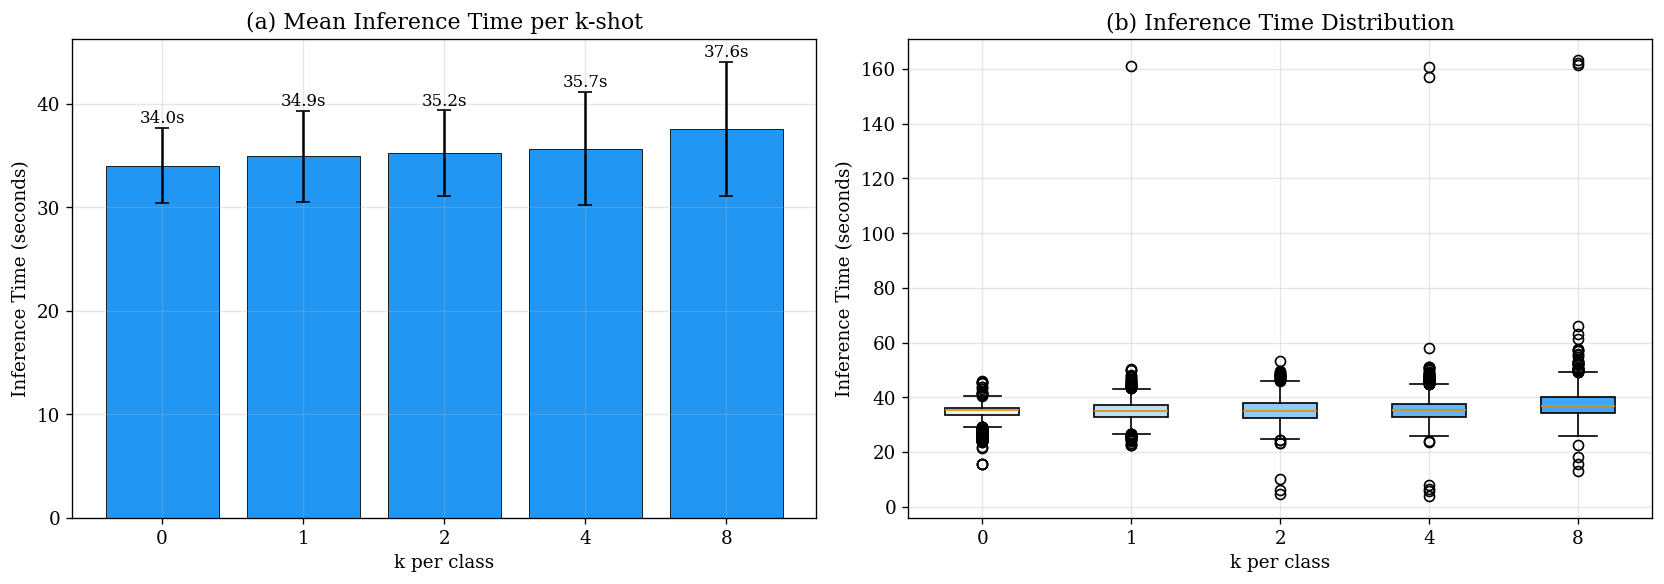

Saved: fig6_inference_time


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Mean inference time per k
ax = axes[0]
time_stats = df.groupby('k_shot')['inference_time'].agg(['mean', 'std']).reset_index()
ax.bar(
    time_stats['k_shot'].astype(str), time_stats['mean'],
    yerr=time_stats['std'], capsize=4,
    color='#2196F3', edgecolor='black', linewidth=0.5
)
for i, row in time_stats.iterrows():
    ax.text(i, row['mean'] + row['std'] + 0.5, f"{row['mean']:.1f}s",
            ha='center', fontsize=10)
ax.set_xlabel('k per class')
ax.set_ylabel('Inference Time (seconds)')
ax.set_title('(a) Mean Inference Time per k-shot')

# (b) Distribution boxplot
ax = axes[1]
k_shots_sorted = sorted(df['k_shot'].unique())
box_data = [df[df['k_shot'] == k]['inference_time'].values for k in k_shots_sorted]
bp = ax.boxplot(box_data, labels=[str(k) for k in k_shots_sorted], patch_artist=True)
colors_box = ['#E3F2FD', '#BBDEFB', '#90CAF9', '#64B5F6', '#42A5F5']
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
ax.set_xlabel('k per class')
ax.set_ylabel('Inference Time (seconds)')
ax.set_title('(b) Inference Time Distribution')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig6_inference_time.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig6_inference_time.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig6_inference_time')

## 10 — Figure 7: Generalization Gap (Internal vs External)

In [10]:
# Compute per-seed accuracy for both test sets
gap_rows = []
for k in sorted(per_seed_df['k_shot'].unique()):
    for seed in sorted(per_seed_df['seed'].unique()):
        int_row = per_seed_df[
            (per_seed_df['k_shot'] == k) & (per_seed_df['seed'] == seed) &
            (per_seed_df['test_set'] == 'CheXpert Plus (Internal)')
        ]
        ext_row = per_seed_df[
            (per_seed_df['k_shot'] == k) & (per_seed_df['seed'] == seed) &
            (per_seed_df['test_set'] == 'RS UNAIR (External)')
        ]
        if len(int_row) > 0 and len(ext_row) > 0:
            gap_rows.append({
                'k_shot': k, 'seed': seed,
                'acc_internal': int_row.iloc[0]['accuracy'],
                'acc_external': ext_row.iloc[0]['accuracy'],
                'f1_internal': int_row.iloc[0]['f1'],
                'f1_external': ext_row.iloc[0]['f1'],
            })

gap_df = pd.DataFrame(gap_rows)
gap_df['acc_gap'] = gap_df['acc_internal'] - gap_df['acc_external']
gap_df['f1_gap'] = gap_df['f1_internal'] - gap_df['f1_external']

# Summary
gap_summary = gap_df.groupby('k_shot').agg({
    'acc_internal': ['mean', 'std'],
    'acc_external': ['mean', 'std'],
    'acc_gap': ['mean', 'std'],
    'f1_internal': ['mean', 'std'],
    'f1_external': ['mean', 'std'],
    'f1_gap': ['mean', 'std'],
}).reset_index()
gap_summary.columns = ['_'.join(c).strip('_') for c in gap_summary.columns]

# Print table
print('Generalization Gap (Accuracy):')
print(f'{"k":>3} | {"Internal":>15} | {"External":>15} | {"Gap (Int-Ext)":>15}')
print('-' * 55)
for _, r in gap_summary.iterrows():
    print(f"{int(r['k_shot']):3d} | "
          f"{r['acc_internal_mean']:.4f}\u00b1{r['acc_internal_std']:.4f} | "
          f"{r['acc_external_mean']:.4f}\u00b1{r['acc_external_std']:.4f} | "
          f"{r['acc_gap_mean']:+.4f}\u00b1{r['acc_gap_std']:.4f}")

print(f'\nGeneralization Gap (F1):')
print(f'{"k":>3} | {"Internal":>15} | {"External":>15} | {"Gap (Int-Ext)":>15}')
print('-' * 55)
for _, r in gap_summary.iterrows():
    print(f"{int(r['k_shot']):3d} | "
          f"{r['f1_internal_mean']:.4f}\u00b1{r['f1_internal_std']:.4f} | "
          f"{r['f1_external_mean']:.4f}\u00b1{r['f1_external_std']:.4f} | "
          f"{r['f1_gap_mean']:+.4f}\u00b1{r['f1_gap_std']:.4f}")

Generalization Gap (Accuracy):
  k |        Internal |        External |   Gap (Int-Ext)
-------------------------------------------------------
  0 | 0.5430±0.0045 | 0.4022±0.0059 | +0.1408±0.0097
  1 | 0.5550±0.0468 | 0.4158±0.0299 | +0.1392±0.0182
  2 | 0.5670±0.0271 | 0.4525±0.0352 | +0.1145±0.0256
  4 | 0.5970±0.0104 | 0.5058±0.0249 | +0.0912±0.0210
  8 | 0.6010±0.0147 | 0.5921±0.0285 | +0.0089±0.0234

Generalization Gap (F1):
  k |        Internal |        External |   Gap (Int-Ext)
-------------------------------------------------------
  0 | 0.2370±0.0116 | 0.0857±0.0173 | +0.1513±0.0200
  1 | 0.2377±0.1638 | 0.1158±0.0886 | +0.1219±0.0782
  2 | 0.3238±0.0862 | 0.2175±0.0891 | +0.1063±0.0485
  4 | 0.4700±0.0222 | 0.3550±0.0695 | +0.1150±0.0585
  8 | 0.5312±0.0326 | 0.5494±0.0660 | -0.0182±0.0430


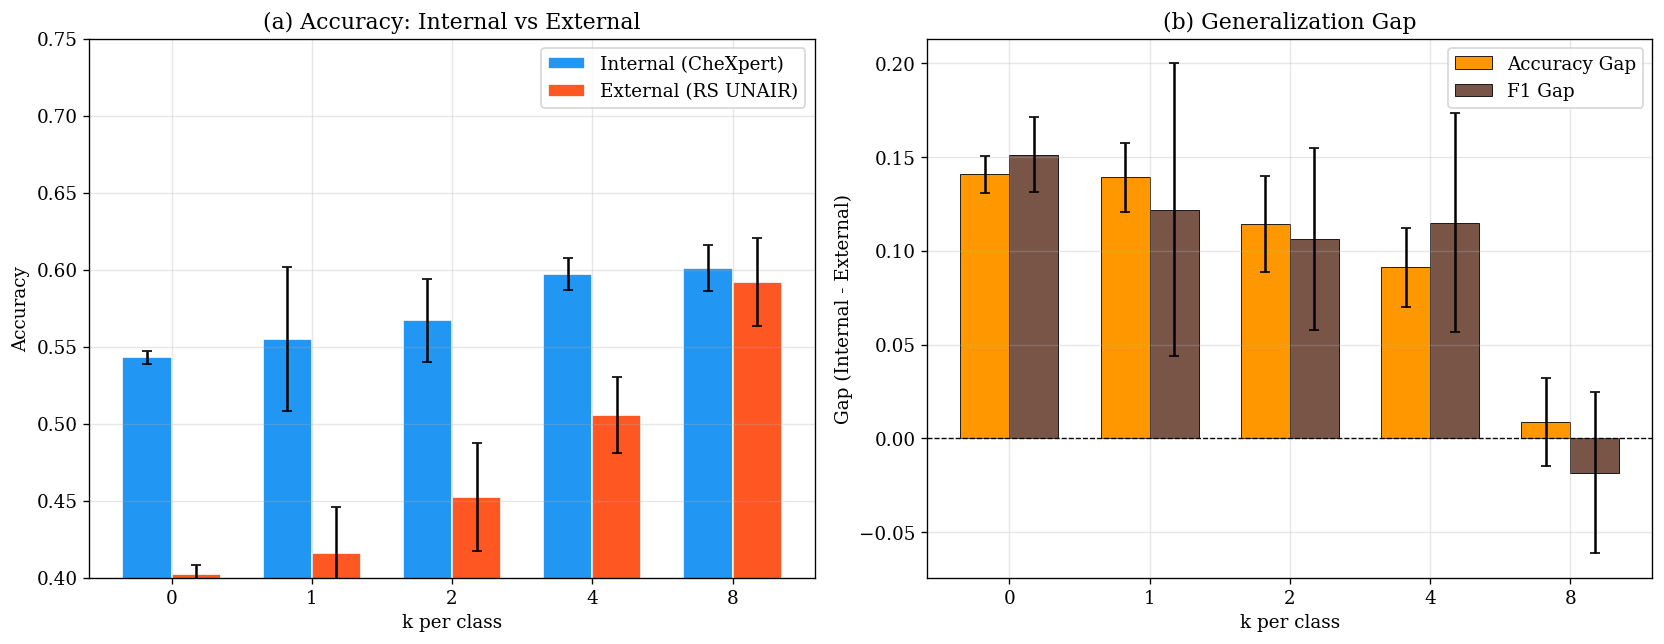

Saved: fig7_generalization_gap


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Side-by-side accuracy
ax = axes[0]
x = np.arange(len(gap_summary))
w = 0.35
ax.bar(x - w/2, gap_summary['acc_internal_mean'], w,
       yerr=gap_summary['acc_internal_std'], label='Internal (CheXpert)',
       color='#2196F3', capsize=3, edgecolor='white')
ax.bar(x + w/2, gap_summary['acc_external_mean'], w,
       yerr=gap_summary['acc_external_std'], label='External (RS UNAIR)',
       color='#FF5722', capsize=3, edgecolor='white')
ax.set_xlabel('k per class')
ax.set_ylabel('Accuracy')
ax.set_title('(a) Accuracy: Internal vs External')
ax.set_xticks(x)
ax.set_xticklabels([str(int(k)) for k in gap_summary['k_shot']])
ax.legend()
ax.set_ylim(0.4, 0.75)

# (b) Gap
ax = axes[1]
ax.bar(x - w/2, gap_summary['acc_gap_mean'], w,
       yerr=gap_summary['acc_gap_std'], label='Accuracy Gap',
       color='#FF9800', capsize=3, edgecolor='black', linewidth=0.5)
ax.bar(x + w/2, gap_summary['f1_gap_mean'], w,
       yerr=gap_summary['f1_gap_std'], label='F1 Gap',
       color='#795548', capsize=3, edgecolor='black', linewidth=0.5)
ax.axhline(y=0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('k per class')
ax.set_ylabel('Gap (Internal - External)')
ax.set_title('(b) Generalization Gap')
ax.set_xticks(x)
ax.set_xticklabels([str(int(k)) for k in gap_summary['k_shot']])
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig7_generalization_gap.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig7_generalization_gap.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig7_generalization_gap')

## 11 — Statistical Significance Tests

In [12]:
from scipy.stats import wilcoxon, mannwhitneyu

print('=' * 65)
print('STATISTICAL TESTS: 0-shot vs k-shot (Wilcoxon signed-rank)')
print('=' * 65)
print('H0: Tidak ada perbedaan performa antara 0-shot dan k-shot')
print('H1: Ada perbedaan performa\n')

for ts in per_seed_df['test_set'].unique():
    print(f'\n--- {ts} ---')
    ts_data = per_seed_df[per_seed_df['test_set'] == ts]
    
    zero_f1 = ts_data[ts_data['k_shot'] == 0].sort_values('seed')['f1'].values
    zero_acc = ts_data[ts_data['k_shot'] == 0].sort_values('seed')['accuracy'].values
    
    for k in [1, 2, 4, 8]:
        k_f1 = ts_data[ts_data['k_shot'] == k].sort_values('seed')['f1'].values
        k_acc = ts_data[ts_data['k_shot'] == k].sort_values('seed')['accuracy'].values
        
        if len(zero_f1) == len(k_f1) and len(zero_f1) >= 5:
            # F1 test
            diff_f1 = k_f1 - zero_f1
            if len(set(diff_f1)) > 1:  # need non-zero differences
                stat_f1, p_f1 = wilcoxon(k_f1, zero_f1)
            else:
                p_f1 = 1.0
            
            # Accuracy test
            diff_acc = k_acc - zero_acc
            if len(set(diff_acc)) > 1:
                stat_acc, p_acc = wilcoxon(k_acc, zero_acc)
            else:
                p_acc = 1.0
            
            sig_f1 = '***' if p_f1 < 0.001 else '**' if p_f1 < 0.01 else '*' if p_f1 < 0.05 else 'ns'
            sig_acc = '***' if p_acc < 0.001 else '**' if p_acc < 0.01 else '*' if p_acc < 0.05 else 'ns'
            
            f1_delta = np.mean(k_f1) - np.mean(zero_f1)
            acc_delta = np.mean(k_acc) - np.mean(zero_acc)
            
            print(f'  0-shot vs {k}-shot:  '
                  f'F1 \u0394={f1_delta:+.4f} p={p_f1:.4f} {sig_f1}  |  '
                  f'Acc \u0394={acc_delta:+.4f} p={p_acc:.4f} {sig_acc}')

STATISTICAL TESTS: 0-shot vs k-shot (Wilcoxon signed-rank)
H0: Tidak ada perbedaan performa antara 0-shot dan k-shot
H1: Ada perbedaan performa


--- CheXpert Plus (Internal) ---
  0-shot vs 1-shot:  F1 Δ=+0.0007 p=1.0000 ns  |  Acc Δ=+0.0120 p=1.0000 ns
  0-shot vs 2-shot:  F1 Δ=+0.0868 p=0.1250 ns  |  Acc Δ=+0.0240 p=0.1875 ns
  0-shot vs 4-shot:  F1 Δ=+0.2330 p=0.0625 ns  |  Acc Δ=+0.0540 p=0.0625 ns
  0-shot vs 8-shot:  F1 Δ=+0.2943 p=0.0625 ns  |  Acc Δ=+0.0580 p=0.0625 ns

--- RS UNAIR (External) ---
  0-shot vs 1-shot:  F1 Δ=+0.0301 p=0.6250 ns  |  Acc Δ=+0.0137 p=0.5000 ns
  0-shot vs 2-shot:  F1 Δ=+0.1318 p=0.0625 ns  |  Acc Δ=+0.0504 p=0.0625 ns
  0-shot vs 4-shot:  F1 Δ=+0.2693 p=0.0625 ns  |  Acc Δ=+0.1036 p=0.0625 ns
  0-shot vs 8-shot:  F1 Δ=+0.4637 p=0.0625 ns  |  Acc Δ=+0.1899 p=0.0625 ns


In [13]:
# Test: Internal vs External per k-shot (Mann-Whitney U)
print('\n' + '=' * 65)
print('STATISTICAL TESTS: Internal vs External (Mann-Whitney U)')
print('=' * 65)
print('H0: Tidak ada perbedaan performa antara Internal dan External')
print('H1: Ada perbedaan performa\n')

for k in sorted(per_seed_df['k_shot'].unique()):
    int_f1 = per_seed_df[
        (per_seed_df['k_shot'] == k) & 
        (per_seed_df['test_set'] == 'CheXpert Plus (Internal)')
    ].sort_values('seed')['f1'].values
    
    ext_f1 = per_seed_df[
        (per_seed_df['k_shot'] == k) & 
        (per_seed_df['test_set'] == 'RS UNAIR (External)')
    ].sort_values('seed')['f1'].values
    
    if len(int_f1) >= 3 and len(ext_f1) >= 3:
        stat, p = mannwhitneyu(int_f1, ext_f1, alternative='two-sided')
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f'  k={k}:  Internal F1={np.mean(int_f1):.4f}  External F1={np.mean(ext_f1):.4f}  '
              f'p={p:.4f} {sig}')


STATISTICAL TESTS: Internal vs External (Mann-Whitney U)
H0: Tidak ada perbedaan performa antara Internal dan External
H1: Ada perbedaan performa

  k=0:  Internal F1=0.2370  External F1=0.0857  p=0.0119 *
  k=1:  Internal F1=0.2377  External F1=0.1158  p=0.2222 ns
  k=2:  Internal F1=0.3238  External F1=0.2175  p=0.1508 ns
  k=4:  Internal F1=0.4700  External F1=0.3550  p=0.0361 *
  k=8:  Internal F1=0.5312  External F1=0.5494  p=0.4206 ns


## 12 — Figure 8: Heatmap Summary Table

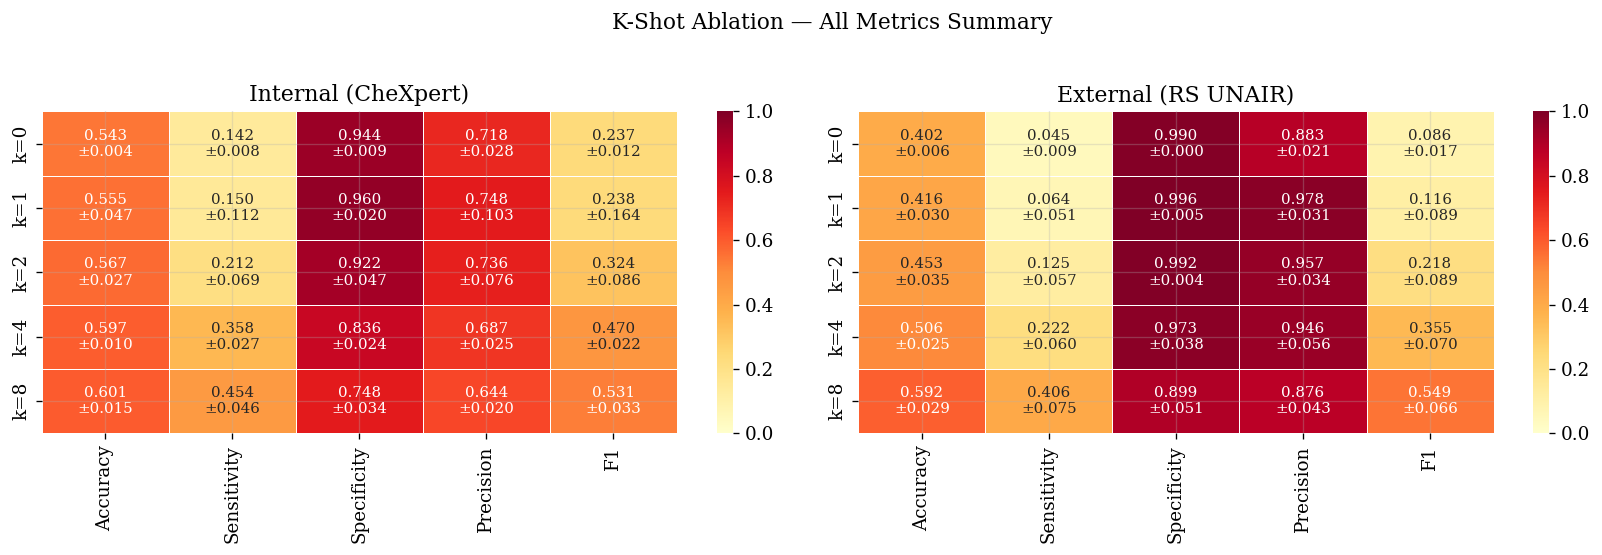

Saved: fig8_heatmap_summary


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for idx, ts in enumerate(test_sets):
    ax = axes[idx]
    sub = summary_df[summary_df['test_set'] == ts].sort_values('k_shot')
    
    # Build matrix
    data = sub[[f'{m}_mean' for m in METRIC_COLS]].values
    
    # Annotations with mean +/- std
    annot_arr = []
    for i, (_, r) in enumerate(sub.iterrows()):
        row_annot = []
        for m in METRIC_COLS:
            row_annot.append(f"{r[f'{m}_mean']:.3f}\n\u00b1{r[f'{m}_std']:.3f}")
        annot_arr.append(row_annot)
    annot_arr = np.array(annot_arr)
    
    sns.heatmap(
        data, annot=annot_arr, fmt='',
        xticklabels=[m.capitalize() for m in METRIC_COLS],
        yticklabels=[f'k={int(k)}' for k in sub['k_shot']],
        cmap='YlOrRd', vmin=0.0, vmax=1.0,
        ax=ax, annot_kws={'fontsize': 9},
        linewidths=0.5
    )
    short_ts = 'Internal (CheXpert)' if 'Internal' in ts else 'External (RS UNAIR)'
    ax.set_title(short_ts)

plt.suptitle('K-Shot Ablation — All Metrics Summary', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig8_heatmap_summary.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig8_heatmap_summary.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig8_heatmap_summary')

## 13 — Sample Model Outputs (Qualitative)

In [15]:
# Tampilkan beberapa contoh output model: correct vs incorrect

df['correct'] = df['predicted'] == df['ground_truth']

# Pick from k=0 for simplicity
k0 = df[(df['k_shot'] == 0) & (df['seed'] == 0)]

print('='*65)
print('CORRECT PREDICTIONS (k=0, seed=0) — 3 examples')
print('='*65)
correct_samples = k0[k0['correct']].head(3)
for _, r in correct_samples.iterrows():
    print(f"\n[{r['test_set']}] {r['image_id']}")
    print(f"  GT={r['ground_truth']}  Pred={r['predicted']}")
    # Extract answer tag
    ans = re.search(r'<answer>(.*?)</answer>', r['generated_text'], re.DOTALL)
    if ans:
        print(f"  Answer: {ans.group(1).strip()}")
    # Show first 200 chars of think
    think = re.search(r'<think>(.*?)</think>', r['generated_text'], re.DOTALL)
    if think:
        snippet = think.group(1).strip()[:200]
        print(f"  Think: {snippet}...")

print(f"\n\n{'='*65}")
print('INCORRECT PREDICTIONS (k=0, seed=0) — 3 examples')
print('='*65)
incorrect_samples = k0[~k0['correct']].head(3)
for _, r in incorrect_samples.iterrows():
    print(f"\n[{r['test_set']}] {r['image_id']}")
    print(f"  GT={r['ground_truth']}  Pred={r['predicted']}")
    ans = re.search(r'<answer>(.*?)</answer>', r['generated_text'], re.DOTALL)
    if ans:
        print(f"  Answer: {ans.group(1).strip()}")
    think = re.search(r'<think>(.*?)</think>', r['generated_text'], re.DOTALL)
    if think:
        snippet = think.group(1).strip()[:200]
        print(f"  Think: {snippet}...")

CORRECT PREDICTIONS (k=0, seed=0) — 3 examples

[CheXpert Plus (Internal)] patient23439_study5_view1_frontal
  GT=1  Pred=1

[CheXpert Plus (Internal)] patient35623_study2_view1_frontal
  GT=1  Pred=1

[CheXpert Plus (Internal)] patient59906_study2_view1_frontal
  GT=1  Pred=1


INCORRECT PREDICTIONS (k=0, seed=0) — 3 examples

[CheXpert Plus (Internal)] patient49816_study1_view1_frontal
  GT=1  Pred=0

[CheXpert Plus (Internal)] patient51966_study2_view1_frontal
  GT=1  Pred=0

[CheXpert Plus (Internal)] patient10406_study1_view1_frontal
  GT=1  Pred=0


## 14 — Error Analysis: False Positives vs False Negatives

In [ ]:
# Aggregate FP/FN rates across k-shots
error_rows = []
for (k, ts), grp in df.groupby(['k_shot', 'test_set']):
    n_total = len(grp)
    n_pos = (grp['ground_truth'] == 1).sum()
    n_neg = (grp['ground_truth'] == 0).sum()
    
    fp = ((grp['predicted'] == 1) & (grp['ground_truth'] == 0)).sum()
    fn = ((grp['predicted'] == 0) & (grp['ground_truth'] == 1)).sum()
    
    error_rows.append({
        'k_shot': k, 'test_set': ts,
        'fp_rate': fp / n_neg if n_neg > 0 else 0,  # = 1 - specificity
        'fn_rate': fn / n_pos if n_pos > 0 else 0,  # = 1 - sensitivity (miss rate)
        'fp_count': fp, 'fn_count': fn,
        'n_pos': n_pos, 'n_neg': n_neg,
    })

error_df = pd.DataFrame(error_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_sets):
    ax = axes[idx]
    sub = error_df[error_df['test_set'] == ts].sort_values('k_shot')
    
    x = np.arange(len(sub))
    w = 0.35
    ax.bar(x - w/2, sub['fp_rate'], w, label='False Positive Rate (1-Spec)',
           color='#FF5722', edgecolor='white')
    ax.bar(x + w/2, sub['fn_rate'], w, label='False Negative Rate (1-Sens)',
           color='#3F51B5', edgecolor='white')
    
    ax.set_xlabel('k per class')
    ax.set_ylabel('Error Rate')
    ax.set_title(ts)
    ax.set_xticks(x)
    ax.set_xticklabels([str(int(k)) for k in sub['k_shot']])
    ax.legend(fontsize=9)
    ax.set_ylim(0, 1.0)

plt.suptitle('Error Analysis: FP Rate vs FN Rate', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig9_error_analysis.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig9_error_analysis.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig9_error_analysis')

# Print table
print('\nError Counts:')
print(error_df[['k_shot', 'test_set', 'fp_count', 'fn_count', 'fp_rate', 'fn_rate']].to_string(index=False))

## 15 — Export Summary Tables (CSV)

In [ ]:
# Save all computed tables
summary_df.to_csv(FIGURES_DIR / 'table_kshot_summary.csv', index=False)
per_seed_df.to_csv(FIGURES_DIR / 'table_per_seed_metrics.csv', index=False)
gap_df.to_csv(FIGURES_DIR / 'table_generalization_gap.csv', index=False)
error_df.to_csv(FIGURES_DIR / 'table_error_analysis.csv', index=False)

print('Exported CSV files to', FIGURES_DIR)
for f in sorted(FIGURES_DIR.glob('*.csv')):
    print(f'  {f.name}')

print(f'\nExported figures:')
for f in sorted(FIGURES_DIR.glob('fig*')):
    print(f'  {f.name}')

## 16 — Key Findings Summary

In [ ]:
print('='*65)
print('KEY FINDINGS — Experiment 1: K-Shot Ablation')
print('='*65)

# Best k by F1 per test set
for ts in summary_df['test_set'].unique():
    sub = summary_df[summary_df['test_set'] == ts]
    best_f1_row = sub.loc[sub['f1_mean'].idxmax()]
    best_acc_row = sub.loc[sub['accuracy_mean'].idxmax()]
    
    print(f'\n--- {ts} ---')
    print(f'  Best k by F1:       k={int(best_f1_row["k_shot"])} '
          f'(F1={best_f1_row["f1_mean"]:.4f}\u00b1{best_f1_row["f1_std"]:.4f})')
    print(f'  Best k by Accuracy: k={int(best_acc_row["k_shot"])} '
          f'(Acc={best_acc_row["accuracy_mean"]:.4f}\u00b1{best_acc_row["accuracy_std"]:.4f})')
    
    # 0-shot baseline
    zero = sub[sub['k_shot'] == 0].iloc[0]
    print(f'  0-shot baseline:    F1={zero["f1_mean"]:.4f}, Acc={zero["accuracy_mean"]:.4f}')
    print(f'  Improvement (F1):   {best_f1_row["f1_mean"] - zero["f1_mean"]:+.4f}')

# Sensitivity-Specificity trade-off observation
print(f'\n--- Observations ---')
print(f'  1. Few-shot meningkatkan Sensitivity (deteksi PTX) tapi menurunkan Specificity')
print(f'     → Model jadi lebih "agresif" mendeteksi pneumothorax dengan lebih banyak contoh')
print(f'  2. F1 meningkat karena gain di Sensitivity > loss di Specificity')
print(f'  3. Best k untuk Experiment 2: k={best_k} (berdasarkan F1 internal)')